# Flower Classification Project

Your task is to **classify photos of flowers as roses, sunflowers or tulips**, with only 100 photos per kind of flower to learn from, using **transfer learning**.

# The Business Problem

A garden centre runs a website where customers upload a photo of a flower from their garden and receive a care guide for it: when to water, when to cut it back, which pests to watch for. At the moment, a member of staff looks at every photo and chooses the right guide by hand. The garden centre starts with its three most requested guides, **roses, sunflowers and tulips**, and wants a model that chooses the guide automatically from the photo.

Your model answers this question: given a photo, which of the three flowers does it show? A wrong answer sends a customer the wrong care guide, so at the end you look at **which photos the model gets wrong**, so that the garden centre knows when to trust it and when a member of staff should check the answer.

The model can only answer with one of the three flowers. A photo of a daisy would still receive one of the three labels, so the website has to make clear which flowers the service covers.

# Data Description

The data ships with this repository in the folder `data/`: **390 colour photos**, one JPEG file per photo, sorted into one folder per kind of flower. The name of the folder is the label of the photo.

| Folder | Photos | Description |
| :-- | :-- | :-- |
| `data/train/rose` | 100 | roses, for training |
| `data/train/sunflower` | 100 | sunflowers, for training |
| `data/train/tulip` | 100 | tulips, for training |
| `data/validation/rose` | 20 | roses, for choosing the model |
| `data/validation/sunflower` | 20 | sunflowers, for choosing the model |
| `data/validation/tulip` | 20 | tulips, for choosing the model |
| `data/test/rose` | 10 | roses, **the test set** |
| `data/test/sunflower` | 10 | sunflowers, **the test set** |
| `data/test/tulip` | 10 | tulips, **the test set** |

The photos have different sizes, from 159 to 640 pixels wide, and show the flowers in very different ways: a single flower close up, a whole field, a bunch in a vase, sometimes with people or buildings in the picture.

The photos are part of the [TensorFlow flower photos](https://www.tensorflow.org/datasets/catalog/tf_flowers) collection and were taken from Flickr. Every photo is licensed under [CC BY 2.0](https://creativecommons.org/licenses/by/2.0/); its photographer is listed in `data/LICENSE.txt`.

## Task

1. **Get the data.** Display a few photos of every class from `data/train`.
2. **Load the training and the validation images.** Load `data/train` and `data/validation` with `keras.utils.image_dataset_from_directory`, with one `image_size` that you use for every model, for example `(160, 160)`. Shuffle the training images with a fixed `seed`; keep the validation images in their order with `shuffle=False`. Do not load `data/test` until step 6.
3. **Explore the training set.** Display a grid of training photos with their labels. What makes the three flowers look different: colour, shape, the background?
4. **Repurpose a pretrained network.** Use `MobileNetV2` from `keras.applications` as the pretrained network and repurpose it to classify the three flowers. Plot its learning curves: does it overfit?

> [!IMPORTANT]
> **Every image has to be prepared in exactly the same way**: the same `image_size`, the same `preprocess_input` of the base, and the same frozen base, for the training, the validation and later the test images.

5. **If needed, improve the model with data augmentation**, and compare the validation accuracy with step 4. Choose your best model by its validation accuracy. **Save every model to a file** with `model.save`, for example `models/dense_head.keras`, so that you can load all of them in step 6 with `keras.models.load_model`, even after restarting the notebook.
6. **Evaluate all models on the test set at the very end.** Load your saved models, and load `data/test` with the same `image_size` and with `shuffle=False`. Then:
    1. Collect the **validation and test accuracy of every model** in **one table**. Is the validation accuracy of your chosen model a fair estimate of its test accuracy? The test set has only 30 photos, so **one photo changes the test accuracy by 3.3 percentage points**.
    2. **Plot the confusion matrix** of your best model on the test set. Which flowers does it confuse?
    3. **Display every misclassified test photo**, with its true and predicted label. What do these photos have in common?
7. **Try your model in an app.** The repository contains a small [Streamlit](https://docs.streamlit.io/) app, `app.py`, that loads a model from `models/` and classifies a photo that you upload. Start it in a terminal in the repository folder with `uv run streamlit run app.py`, choose your best model, and upload a few flower photos of your own. Does the model get them right? The app works with models that take the raw photos and include their preprocessing, such as `preprocess_input`, as layers.

In [1]:
# Import the libraries you need for this project
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # hide TensorFlow's start-up info messages

import time
from pathlib import Path

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from keras.applications import mobilenet_v2
from matplotlib.colors import rgb_to_hsv
from PIL import Image

from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

## How to read this notebook

We work through the seven steps one question at a time. For each step we first write down **our guess**, then look at the photos, then **decide**. A *Questions and answers* table after each step records guess, evidence and decision, so that everyone in the group can follow why the notebook looks the way it does.

The training photos are explored. The validation photos are only counted, checked for copies of training photos and then used to choose the model. The test photos stay locked until step 6 and are used exactly once.

## Goal, metric and success criterion (fixed before looking at the photos)

| Decision | Choice | Why |
| :-- | :-- | :-- |
| Metric | **Accuracy**: the share of photos that get the right care guide | Every folder has the same number of photos per flower (100 / 20 / 10), so accuracy is not distorted by one large class. A model that always names the same flower gets 33 % |
| Success criterion | **At least 90 % validation accuracy**, that is at most 6 of the 60 validation photos wrong | Below that, staff would still have to check too many photos by hand. One validation photo is worth 1.7 percentage points, one test photo 3.3. We do not lower it later if a model misses it |
| Image size | **160 × 160 for every model** | The task suggests it, and Keras ships ImageNet weights of MobileNetV2 for this size (96, 128, 160, 192 or 224 pixels). (160 / 224)² = 0.51, so a photo costs about half the computation of 224 × 224 |
| Extra 1 | **A confidence threshold**: below it, a member of staff checks the photo | Answers the business question "when can we trust the model?". Chosen on the validation photos, applied once to the test photos |
| Extra 2 | **A nicer app** for step 7 | The coaches asked us to experiment; the app is what the garden centre's customers would see |

## Step 1: Get the data

In [2]:
# Step 1: one folder per flower, the folder name is the label. Only train/ and
# validation/ are counted here: test/ stays locked until step 6
DATA = Path("data")
CLASSES = sorted(p.name for p in (DATA / "train").iterdir() if p.is_dir())
counts = pd.DataFrame({split: {flower: len(list((DATA / split / flower).glob("*.jpg"))) for flower in CLASSES}
                       for split in ["train", "validation"]})
print("classes:", CLASSES)
counts

classes: ['rose', 'sunflower', 'tulip']


,train,validation
rose,100,20
sunflower,100,20
tulip,100,20


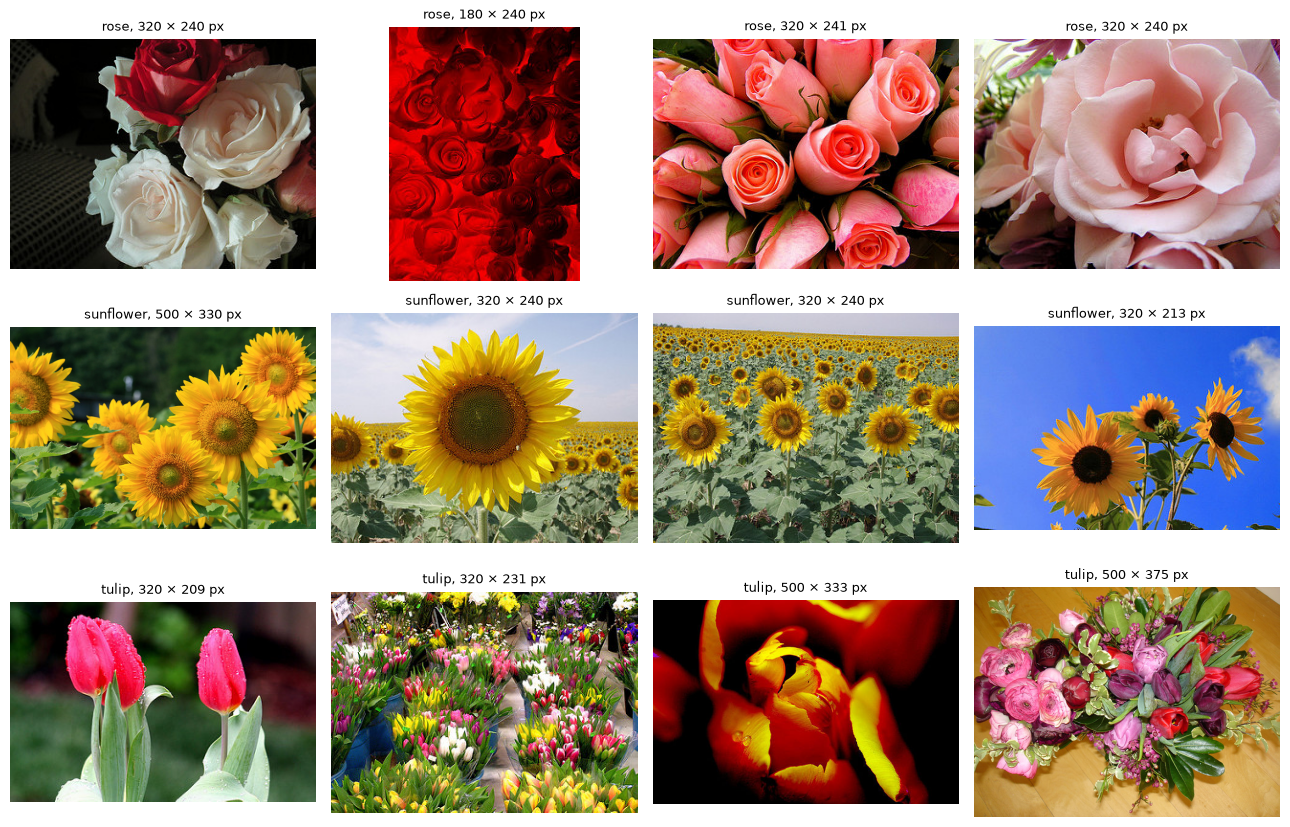

In [3]:
# A few photos of every class from data/train, in their original shape and size
# (the first four files of each folder by name, so the grid is the same on every run)
fig, axes = plt.subplots(len(CLASSES), 4, figsize=(13, 8.5))
for row, flower in zip(axes, CLASSES):
    for ax, path in zip(row, sorted((DATA / "train" / flower).glob("*.jpg"))[:4]):
        with Image.open(path) as img:
            ax.imshow(img)
            ax.set_title(f"{flower}, {img.width} × {img.height} px", fontsize=9)
        ax.axis("off")
plt.tight_layout()
plt.show()

## Step 2: Load the training and the validation images

In [4]:
# Step 2: batches of (images, labels). One IMAGE_SIZE for every model. Training photos are
# shuffled with a fixed seed; validation photos keep their order (shuffle=False), so that
# predictions can later be matched to the files. No crop: every photo is squeezed to
# 160 x 160, exactly as app.py does it (tf.image.resize), so training and app agree
IMAGE_SIZE = (160, 160)
SEED = 42
keras.utils.set_random_seed(SEED)
train_ds = keras.utils.image_dataset_from_directory(
    DATA / "train", image_size=IMAGE_SIZE, batch_size=32, shuffle=True, seed=SEED)
val_ds = keras.utils.image_dataset_from_directory(
    DATA / "validation", image_size=IMAGE_SIZE, batch_size=32, shuffle=False)
print("class names:", train_ds.class_names, "| same order in validation:",
      train_ds.class_names == val_ds.class_names == CLASSES)

Found 300 files belonging to 3 classes.


Found 60 files belonging to 3 classes.


class names: ['rose', 'sunflower', 'tulip'] | same order in validation: True


In [5]:
# What one batch looks like: 32 photos of 160 x 160 x 3 colour values, still 0 to 255
# (no preprocessing yet), and integer labels 0, 1, 2 in the alphabetical order of the folders
images, labels = next(iter(train_ds))
print("images:", images.shape, images.dtype,
      f"| pixel values {float(images.numpy().min()):.0f} to {float(images.numpy().max()):.0f}")
print("labels:", labels.shape, labels.dtype, "| first ten:", labels.numpy()[:10])

images: (32, 160, 160, 3) <dtype: 'float32'> | pixel values 0 to 255
labels: (32,) <dtype: 'int32'> | first ten: [1 0 1 0 1 0 2 0 1 2]


**Steps 1 and 2 in questions and answers**

| Question | Answer |
| :-- | :-- |
| How many photos per flower? | 100 per flower in training, 20 in validation, balanced (test: 10 per flower, not opened) |
| What do the photos show? | Very different scenes: single blossoms close up, bunches, whole fields, a market stall, a bouquet on a table. The twelve photos above are 180 to 500 pixels wide and mostly landscape |
| Which labels does the model learn? | `rose` = 0, `sunflower` = 1, `tulip` = 2, from the folder names in alphabetical order; the same order in training and validation |
| What does a batch contain? | 32 photos of 160 × 160 × 3 values from 0 to 255 (`float32`), plus 32 integer labels. MobileNetV2 expects −1 to 1, and `app.py` passes raw 0 to 255 pixels, so the preprocessing has to be a layer inside the saved model (step 4) |
| Why squeeze instead of crop? | `app.py` squeezes the uploaded photo with `tf.image.resize`. If training cropped, the app would show the model photos prepared differently from the training photos |

## Step 3: Explore the training set

(300, 160, 160, 3) | photos per class: {'rose': 100, 'sunflower': 100, 'tulip': 100}


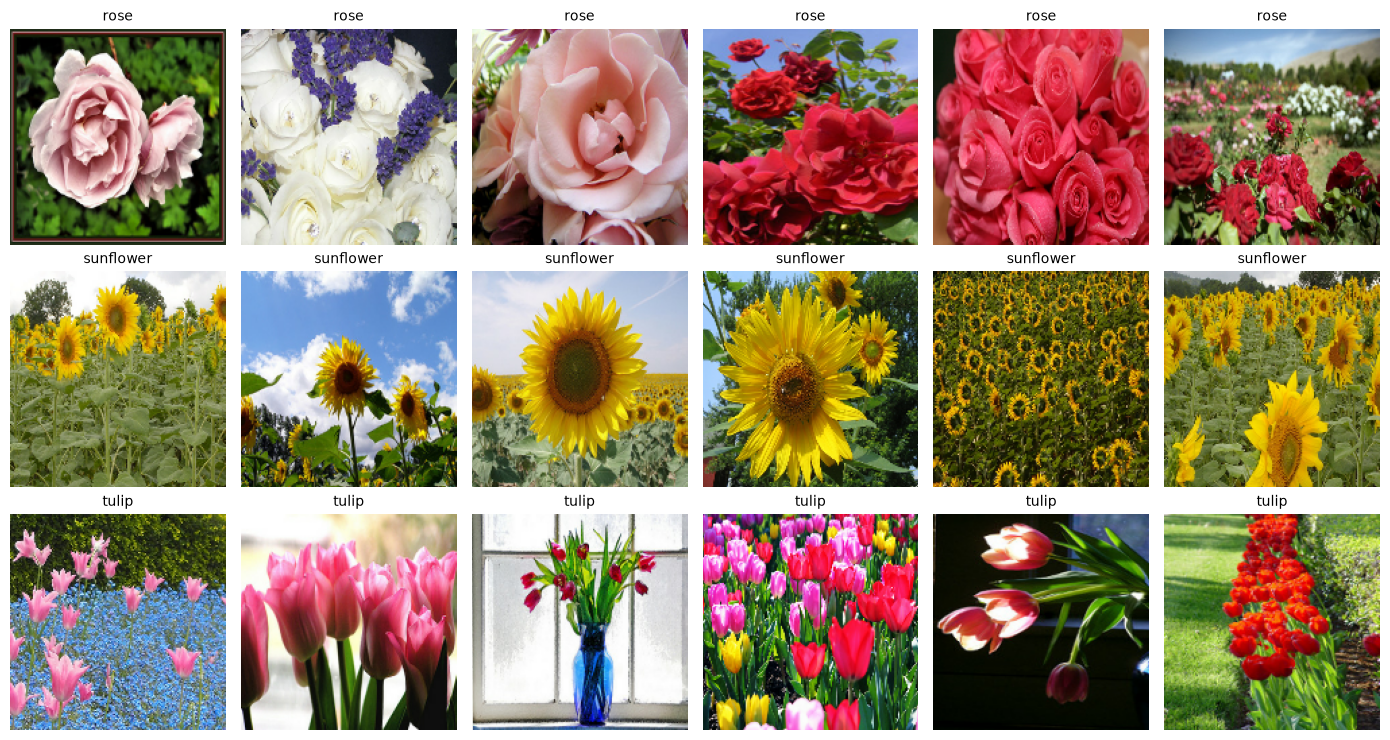

In [6]:
# 3.1 All 300 training photos in memory, for exploring only (uint8; the models train on
# train_ds). Images and labels come from the SAME loop: train_ds reshuffles on every pass,
# so two separate loops would mismatch them
batches = [(x.numpy().astype("uint8"), y.numpy()) for x, y in train_ds]
X_train = np.concatenate([x for x, _ in batches])
y_train = np.concatenate([y for _, y in batches])
print(X_train.shape, "| photos per class:", dict(zip(CLASSES, np.bincount(y_train).tolist())))

# Six photos per class, as the model sees them: squeezed to 160 x 160
fig, axes = plt.subplots(len(CLASSES), 6, figsize=(14, 7.5))
for k, row in enumerate(axes):
    for ax, img in zip(row, X_train[y_train == k][:6]):
        ax.imshow(img)
        ax.set_title(CLASSES[k], fontsize=10)
        ax.axis("off")
plt.tight_layout()
plt.show()

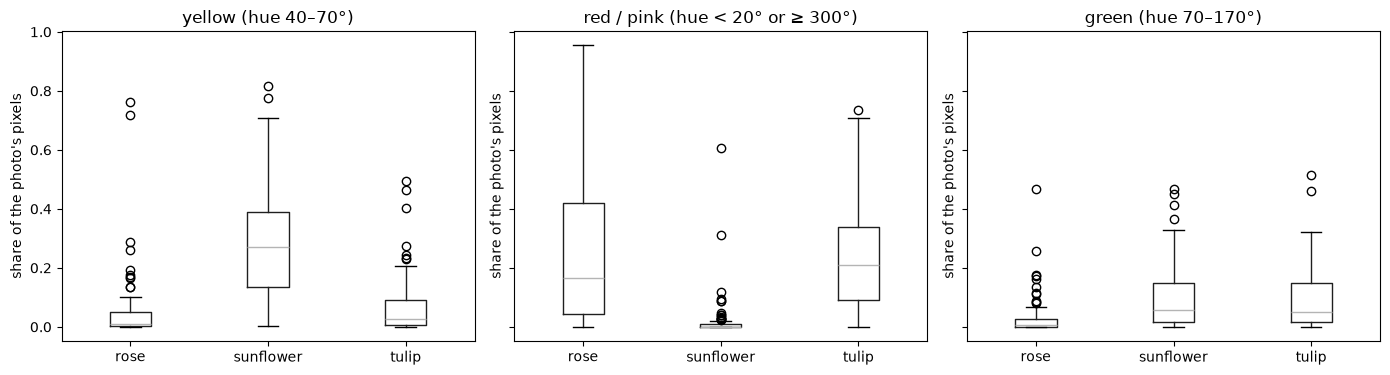

,yellow (hue 40–70°),red / pink (hue < 20° or ≥ 300°),green (hue 70–170°)
flower,,,
rose,0.011,0.166,0.006
sunflower,0.270,0.001,0.057
tulip,0.027,0.209,0.052


In [7]:
# 3.2 Colour: per photo, the share of its pixels that are clearly yellow, red/pink or green
# (hue of the HSV colour model; grey, dark and pale pixels do not count). One box per flower
hsv = rgb_to_hsv(X_train / 255.0)
hue, vivid = hsv[..., 0] * 360, (hsv[..., 1] > 0.35) & (hsv[..., 2] > 0.35)
bands = {"yellow (hue 40–70°)": (hue >= 40) & (hue < 70),
         "red / pink (hue < 20° or ≥ 300°)": (hue < 20) | (hue >= 300),
         "green (hue 70–170°)": (hue >= 70) & (hue < 170)}
colour = pd.DataFrame({name: (band & vivid).mean(axis=(1, 2)) for name, band in bands.items()})
colour["flower"] = np.array(CLASSES)[y_train]
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, name in zip(axes, bands):
    colour.boxplot(column=name, by="flower", ax=ax, grid=False)
    ax.set(title=name, xlabel="", ylabel="share of the photo's pixels")
plt.suptitle("")
plt.tight_layout()
plt.show()
colour.groupby("flower").median().round(3)

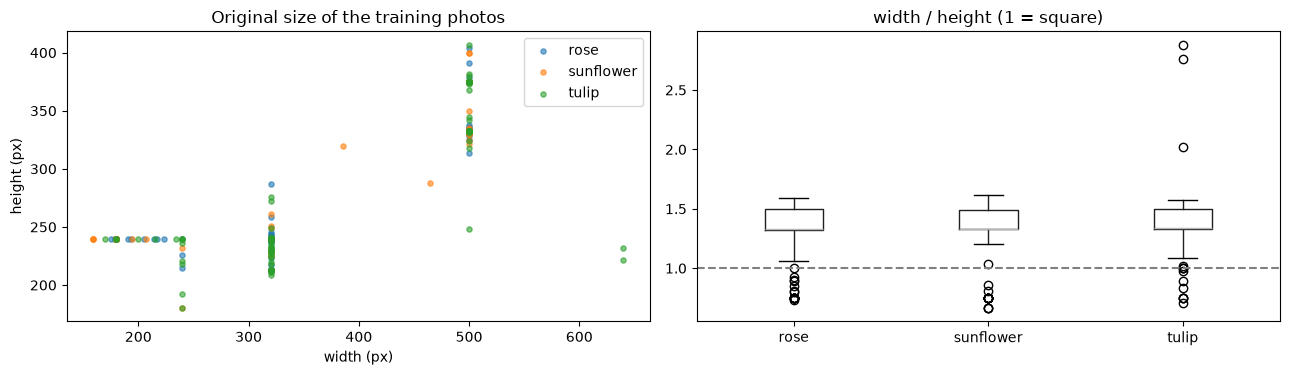

,width,height,aspect
flower,,,
rose,320.0,245.0,1.33
sunflower,320.0,256.0,1.33
tulip,320.0,240.0,1.34


In [8]:
# 3.3 Original sizes. Every photo is squeezed to 160 x 160 without cropping. How much does
# that distort? width / height = 1 means square, 1.5 means a 3:2 landscape photo
sizes = []
for flower in CLASSES:
    for path in sorted((DATA / "train" / flower).glob("*.jpg")):
        with Image.open(path) as img:
            sizes.append({"flower": flower, "width": img.width, "height": img.height})
sizes = pd.DataFrame(sizes)
sizes["aspect"] = sizes["width"] / sizes["height"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for flower, group in sizes.groupby("flower"):
    axes[0].scatter(group["width"], group["height"], s=14, alpha=0.6, label=flower)
axes[0].set(xlabel="width (px)", ylabel="height (px)", title="Original size of the training photos")
axes[0].legend()
sizes.boxplot(column="aspect", by="flower", ax=axes[1], grid=False)
axes[1].axhline(1, color="grey", ls="--")
axes[1].set(title="width / height (1 = square)", xlabel="")
plt.suptitle("")
plt.tight_layout()
plt.show()
sizes.groupby("flower")[["width", "height", "aspect"]].median().round(2)

In [9]:
# 3.4 Is the validation set independent of the training set? (a) The same photographer
# in both, from data/LICENSE.txt. (b) Copies: a difference hash compares the brightness of
# neighbouring pixels on a 9 x 8 thumbnail, 64 bits; below about 10 bits = very likely the
# same photo, resized or re-compressed (crops of the same photo are not detected this way)
credits = {}
for line in (DATA / "LICENSE.txt").read_text(encoding="utf-8").splitlines():
    if " CC-BY by " in line:
        file, rest = line.split(" CC-BY by ", 1)
        credits[file.split("/")[-1]] = rest.rsplit(" - ", 1)[0]

def dhash(path):
    with Image.open(path) as img:
        g = np.asarray(img.convert("L").resize((9, 8)), dtype=int)
    return (g[:, 1:] > g[:, :-1]).flatten()

files = {split: sorted((DATA / split).glob("*/*.jpg")) for split in ["train", "validation"]}
hashes = {split: np.array([dhash(p) for p in paths]) for split, paths in files.items()}
distance = (hashes["validation"][:, None, :] != hashes["train"][None, :, :]).sum(axis=2)
train_photographers = {credits.get(p.name) for p in files["train"]}
shared = np.array([credits.get(p.name) in train_photographers for p in files["validation"]])
print("photos without a credit line:", sum(credits.get(p.name) is None for ps in files.values() for p in ps))
print(f"validation photos whose photographer also appears in training: {shared.sum()} of {len(shared)}")
print("smallest hash distances validation -> training (of 64 bits):", np.sort(distance.min(axis=1))[:8])

photos without a credit line: 0
validation photos whose photographer also appears in training: 6 of 60
smallest hash distances validation -> training (of 64 bits): [14 14 15 15 16 16 16 16]


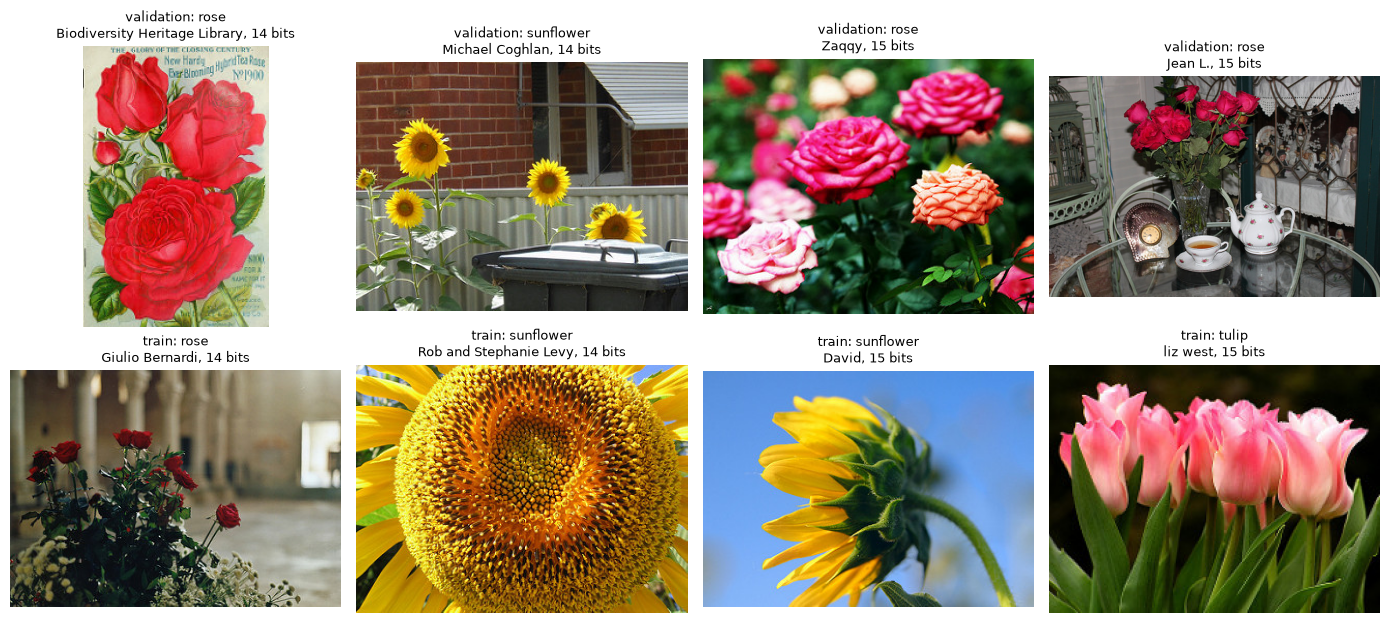

In [10]:
# The four validation photos closest to a training photo, side by side
closest = np.argsort(distance.min(axis=1))[:4]
fig, axes = plt.subplots(2, 4, figsize=(14, 6.5))
for col, v in enumerate(closest):
    t = distance[v].argmin()
    for row, (path, split) in enumerate([(files["validation"][v], "validation"), (files["train"][t], "train")]):
        with Image.open(path) as img:
            axes[row, col].imshow(img)
        axes[row, col].set_title(f"{split}: {path.parent.name}\n{credits.get(path.name)}, {distance[v, t]} bits", fontsize=9)
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

**Step 3 in questions and answers**

| Question | Our guess before the plots | What the training photos say |
| :-- | :-- | :-- |
| What makes the three flowers look different: colour, shape or background? | Colour first; on second thought colour **and** shape, because there are yellow roses and tulips too, and open tulips look like roses | **Both, with a division of labour (3.2).** Colour separates sunflowers: in the median photo 27 % of the pixels are strongly yellow, against 1 % for roses and 3 % for tulips, and red or pink is almost absent (0.1 %). Roses and tulips share their colours (red or pink: 17 % and 21 %), so between those two the shape has to decide. The background differs as well: sunflowers in fields under a blue sky, roses close up and in bunches, tulips in gardens, markets and vases (3.1) |
| Which pair will the model confuse most? | Rose and tulip | From the colours alone: rose and tulip. Checked on the validation photos in step 4.7 |
| Does squeezing to 160 × 160 distort the photos? | – | Yes, by the same amount for every flower: the median photo is 320 × 240 (4:3) in all three classes (3.3), so it loses a quarter of its width. A few portrait photos and three very wide tulip photos are squeezed more. The app squeezes in the same way, so training and use agree |
| Are the validation photos independent of the training photos? | – | Yes (3.4): only 6 of the 60 validation photos come from a photographer who also appears in training, and none is a copy of a training photo (smallest distance 14 of 64 bits; copies would be below about 10). Crops would not be found this way |